In [49]:
import pandas as pd
import numpy as np

In [50]:
df=pd.read_csv("powerplant_data.csv")

In [51]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [52]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [53]:
X=df.drop("PE",axis=1)
y=df["PE"]

In [121]:
X_test

,AT,V,AP,RH
2513,29.70,57.35,1005.63,57.35
9411,25.71,71.64,1008.85,77.31
8745,17.83,44.92,1025.04,70.58
9085,9.46,41.40,1026.78,87.58
4950,29.90,64.79,1016.90,48.24
...,...,...,...,...
7204,20.46,51.43,1010.06,83.79
1599,29.70,67.17,1007.31,66.56
5697,14.64,39.58,1011.46,71.90
350,29.47,71.32,1008.07,67.00


In [55]:
#split out data
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [56]:
df.shape

(9568, 5)

In [57]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [58]:
X_train_scaled

array([[ 0.74805289,  0.72006931, -0.32660017, -0.49711722],
       [ 0.86181948,  1.26515721, -0.98521113,  0.8181501 ],
       [ 0.93409473,  1.52314975,  0.32523844,  0.80167494],
       ...,
       [-0.22097078, -0.834965  ,  0.36756563, -0.83554456],
       [ 0.94747903,  1.14245344, -0.41971997, -0.45455637],
       [-1.77355014, -1.19049131,  1.92520594,  0.91837402]],
      shape=(7654, 4))

In [92]:
import torch
import torch.nn as nn

In [93]:
X_train_tensor=torch.tensor(X_train_scaled,dtype=torch.float)
y_train_tensor=torch.tensor(y_train.values,dtype=torch.float).view(-1,1)
X_test_tensor=torch.tensor(X_test_scaled,dtype=torch.float)
y_test_tensor=torch.tensor(y_test.values,dtype=torch.float).view(-1,1)

In [61]:
type(X_train_scaled)

numpy.ndarray

In [122]:
type(y_train)


pandas.Series

In [96]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

In [97]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32)

## Deep Learning

In [98]:
# Define our ANN Model

class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            # 1st hidden layer
            nn.Linear(X_train.shape[1], 6),
            nn.ReLU(),
    
            # 2nd hidden layer
            nn.Linear(6, 6),
            nn.ReLU(),
    
            # output layer
            nn.Linear(6, 1),
        )

    def forward(self, x):
        return self.model(x)

In [124]:
import torch.optim as optim

model = ANN()

# loss, optimizer
crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [100]:
# Train the ANN
train_losses = []
val_losses = []

best_val_loss = float("inf")

epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # tot training loss for 1 epoch
    
    for xb, yb in train_loader:
        # xb = features of 1 batch
        # yb = labels of 1 batch
        optimizer.zero_grad()
        
        outputs = model(xb) # forward prop....predicted outputs for this batch
        loss = crietrion(outputs, yb) # compute loss
        loss.backward() # back prop.. compute gradients
        optimizer.step() # params update
        
        running_loss += loss.item() # loss is a tensor => py float

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)


    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad(): # no gradients compute
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = crietrion(outputs, yb)
            running_val_loss += loss

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)

    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt") #.pt or .pth

epoch 1/100 ==> train loss = 205694.88372395834 & val loss = 203566.390625
epoch 2/100 ==> train loss = 196348.29765625 & val loss = 184520.796875
epoch 3/100 ==> train loss = 165201.375390625 & val loss = 142160.640625
epoch 4/100 ==> train loss = 116158.51953125 & val loss = 89384.671875
epoch 5/100 ==> train loss = 69071.26751302084 & val loss = 50571.7109375
epoch 6/100 ==> train loss = 38543.84866536458 & val loss = 27172.84375
epoch 7/100 ==> train loss = 20876.6541015625 & val loss = 15272.0537109375
epoch 8/100 ==> train loss = 12790.0187113444 & val loss = 10357.556640625
epoch 9/100 ==> train loss = 9151.259386189779 & val loss = 7628.96875
epoch 10/100 ==> train loss = 6715.887172444662 & val loss = 5479.0439453125
epoch 11/100 ==> train loss = 4721.547267659505 & val loss = 3712.47216796875
epoch 12/100 ==> train loss = 3160.6678853352864 & val loss = 2410.0478515625
epoch 13/100 ==> train loss = 2086.24230855306 & val loss = 1570.584716796875
epoch 14/100 ==> train loss = 

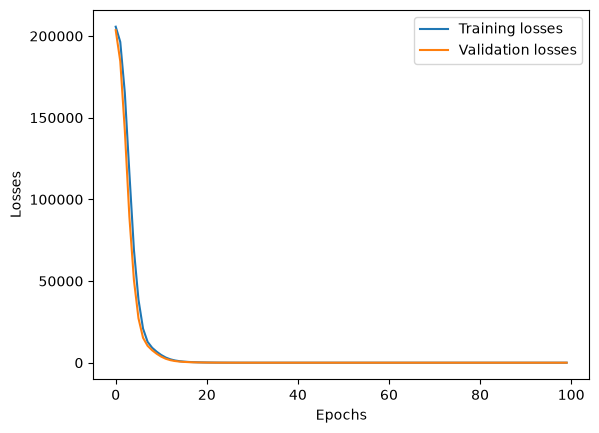

In [107]:
import matplotlib.pyplot as plt
loss_df=pd.DataFrame({
    "Training losses":train_losses,
    "Validation losses":val_losses
})

plt.plot(loss_df["Training losses"],label="Training losses")
plt.plot(loss_df["Validation losses"],label="Validation losses")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [108]:
# load the best model
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [113]:
# Evaluation

model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = crietrion(train_preds, y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)

print("Training MSE:", train_mse_loss.item())
print("Testing MSE:", test_mse_loss.item())

Training MSE: 20.385713577270508
Testing MSE: 18.70412826538086


In [115]:
from sklearn.metrics import r2_score
print("R^2 squared value:",r2_score(y_test,test_preds))


R^2 squared value: 0.9346338910542941


In [117]:
predicted_df=pd.DataFrame(test_preds.numpy(),columns=["Predicted values"])
actual_df=pd.DataFrame(y_test.values,columns=["Actual values"])
pd.concat([predicted_df,actual_df],axis=1)

,Predicted values,Actual values
0,435.400085,433.27
1,436.933075,438.16
2,461.050934,458.42
3,475.878326,480.82
4,435.425690,441.41
...,...,...
1909,451.197113,456.70
1910,431.704285,438.04
1911,467.536163,467.80
1912,431.151123,437.14
